In [1]:
import starfile
from findingampa.utils.analysis import render_active_zonograms, calculate_probit, estimate_anisotropic_gaussian_for_probit, calculate_1q_p_value, render_active_zonograms, select_aunps
import pymeshlab
from pathlib import Path
from scipy.spatial import cKDTree
from matplotlib import pyplot as plt
import torch
import mrcfile
import numpy as np
import json
%matplotlib inline

In [2]:
basefolder = Path("/goliath/processing/Gouaux/CJS/BestTomo/ProcessingCJS/tomograms/15F1_tomograms/TOP_TOMOS/")

tomos = [("20231026_HippAu_14","0")]

In [3]:
def load_tomogram(az):
    with mrcfile.open(az, permissive=True) as mrc:
        res_ddw = torch.tensor(mrc.data.copy())
    
    return res_ddw, res_ddw.shape

In [55]:
az = basefolder / tomos[0][0] / "best_alignment" / "active_zonograms" / f"active_zonogram_{tomos[0][1]}.mrc"
res_ddw, rshape = load_tomogram(az)
fig = render_active_zonograms((None,None,res_ddw))
az_data = np.load(az.with_suffix(".npy") ,allow_pickle=True)
sel_aunps = starfile.read(basefolder / tomos[0][0] / "best_alignment" / "aunps" / f"aunp_tm_BP_active_zone_{tomos[0][1]}.star")
selected_aunp_pos = sel_aunps[["faCoordinateX", "faCoordinateY", "faCoordinateZ"]].values 
selected_aunp_pos_transformed = (selected_aunp_pos - az_data.tolist()["center"]) @ az_data.tolist()["cs"].T
selected_aunp_pos_transformed += np.floor(np.array(rshape)[[2,1,0]]/2)
selected_aunp_pos_transformed = selected_aunp_pos_transformed[np.all(selected_aunp_pos_transformed > 0, axis=1)]
selected_aunp_pos_transformed = selected_aunp_pos_transformed[np.all(selected_aunp_pos_transformed < np.array(rshape)[[2,1,0]], axis=1)]



In [56]:
from scipy.spatial import cKDTree

kdt = cKDTree(selected_aunp_pos_transformed)
pairs = kdt.query_pairs(21,output_type="ndarray")
distances = np.linalg.norm(selected_aunp_pos_transformed[pairs[:,0]] - selected_aunp_pos_transformed[pairs[:,1]], axis=1)
pairs = pairs[distances > 12]



In [57]:
centers = (selected_aunp_pos_transformed[pairs[:,0]] + selected_aunp_pos_transformed[pairs[:,1]])/2
potential_centers = kdt.query(centers, k=1, distance_upper_bound=4)

pairs = pairs[potential_centers[0] < 4]
potential_centers = potential_centers[1][potential_centers[0] < 4]
pt_dis = 8
potential_points = kdt.query_ball_point(selected_aunp_pos_transformed[potential_centers], pt_dis)

potential_ps = []
for i, potential_point_list in enumerate(potential_points):
    for potential_point in potential_point_list:
        if potential_point in pairs[i] or potential_point == potential_centers[i]:
            continue
        if np.linalg.norm(selected_aunp_pos_transformed[pairs[i][0]] - selected_aunp_pos_transformed[potential_point]) < pt_dis:
            potential_ps.append([pairs[i][1], potential_centers[i], pairs[i][0], potential_point])
            continue
        if np.linalg.norm(selected_aunp_pos_transformed[pairs[i][1]] - selected_aunp_pos_transformed[potential_point]) < pt_dis:
            potential_ps.append([pairs[i][0], potential_centers[i], pairs[i][1], potential_point])
            continue


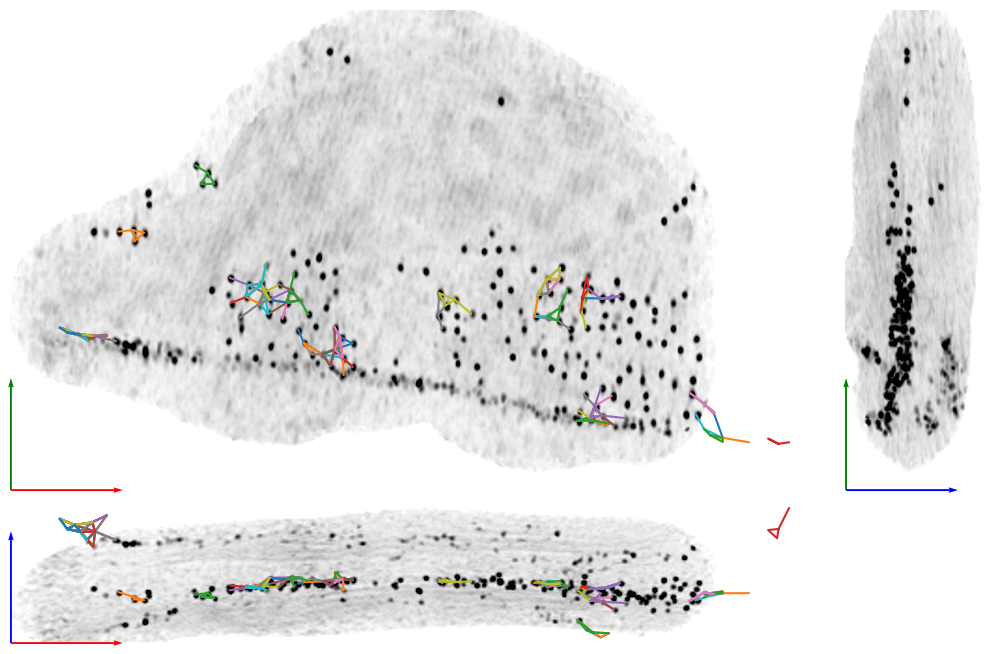

In [58]:

(axxy, axyz, axxz) = fig.get_axes()
for (i, j, k, l) in potential_ps:

    axxy.plot([selected_aunp_pos_transformed[i, 0], selected_aunp_pos_transformed[j, 0], selected_aunp_pos_transformed[k, 0], selected_aunp_pos_transformed[l, 0], selected_aunp_pos_transformed[j, 0]], 
            [selected_aunp_pos_transformed[i, 1], selected_aunp_pos_transformed[j, 1], selected_aunp_pos_transformed[k,1],selected_aunp_pos_transformed[l,1], selected_aunp_pos_transformed[j,1]], "-")
    axxz.plot([selected_aunp_pos_transformed[i, 0], selected_aunp_pos_transformed[j, 0], selected_aunp_pos_transformed[k, 0], selected_aunp_pos_transformed[l, 0], selected_aunp_pos_transformed[j, 0]],
            [selected_aunp_pos_transformed[i, 2], selected_aunp_pos_transformed[j, 2], selected_aunp_pos_transformed[k,2],selected_aunp_pos_transformed[l,2], selected_aunp_pos_transformed[j,2]], "-")
fig

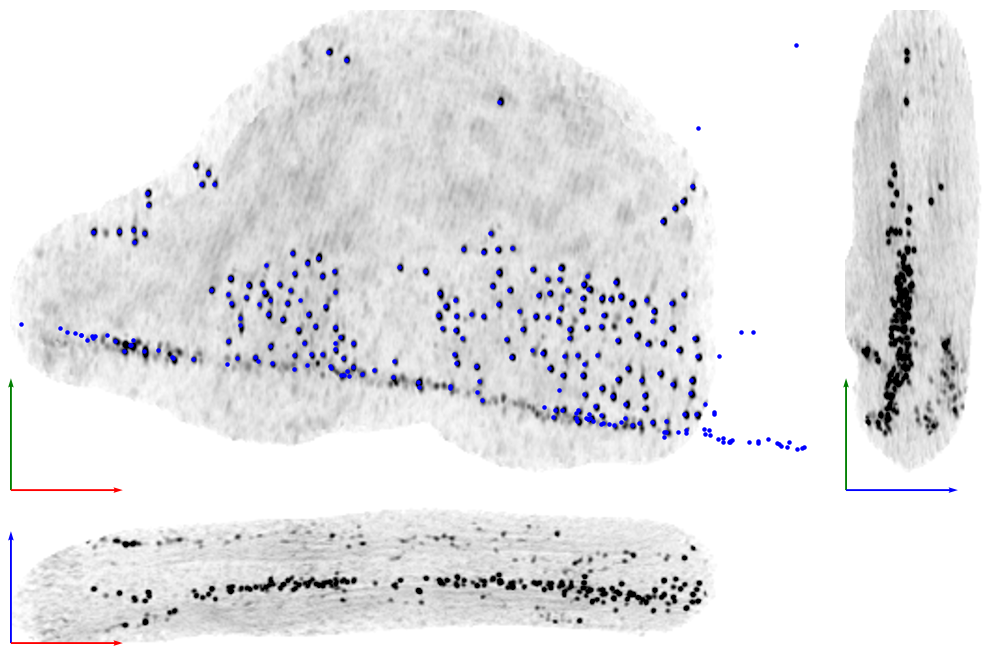

In [59]:
az = basefolder / tomos[0][0] / "best_alignment" / "active_zonograms" / f"active_zonogram_{tomos[0][1]}.mrc"
res_ddw, rshape = load_tomogram(az)
fig = render_active_zonograms((None,None,res_ddw))
az_data = np.load(az.with_suffix(".npy") ,allow_pickle=True)
sel_aunps = starfile.read(basefolder / tomos[0][0] / "best_alignment" / "aunps" / f"aunp_tm_BP_active_zone_{tomos[0][1]}.star")
selected_aunp_pos = sel_aunps[["faCoordinateX", "faCoordinateY", "faCoordinateZ"]].values 
selected_aunp_pos_transformed = (selected_aunp_pos - az_data.tolist()["center"]) @ az_data.tolist()["cs"].T
selected_aunp_pos_transformed += np.floor(np.array(rshape)[[2,1,0]]/2)
selected_aunp_pos_transformed = selected_aunp_pos_transformed[np.all(selected_aunp_pos_transformed > 0, axis=1)]
selected_aunp_pos_transformed = selected_aunp_pos_transformed[np.all(selected_aunp_pos_transformed < np.array(rshape)[[2,1,0]], axis=1)]

(axxy, axxz, axyz) = fig.get_axes()

axxy.scatter(selected_aunp_pos_transformed[:,0], selected_aunp_pos_transformed[:,1], c="b", s=5)

fig